# CYP Fragment Predictive Feature Evaluation

## Objective
Determine whether CYP-relevant chemical fragments improve
the prediction of CYP inhibition potency.

## Experiments
1. Train a model using only CYP fragment features.
2. Train a baseline model using molecular fingerprints.
3. Train a combined model using fingerprints and CYP fragments.
4. Compare prediction error across four CYP isoforms.

## Evaluation
Use held-out RMSE and R² to compare models.

Lower RMSE indicates better predictions.
Higher R² indicates better predictive performance.

All models for a given isoform will use the same
training and testing molecules.

In [7]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score

In [8]:
features = pd.read_csv("../data/cyp_features.csv")

inhibition = pd.read_csv(
    "../data/cyp-challenge-TRAIN_inhibition.csv"
)

with open("../data/cyp_fragment_data.json") as f:
    fragment_data = json.load(f)

feature_cols = [
    frag["id"]
    for frag in fragment_data["fragments"]
    if frag["set"] == "cyp"
]

inhibition = inhibition.rename(
    columns={"SMILES": "smiles"}
)

# Check identifiers before joining
assert features["smiles"].is_unique
assert inhibition["smiles"].is_unique

merged = features.merge(
    inhibition,
    on="smiles",
    how="inner",
    validate="one_to_one"
)

isoforms = ["CYP1A2", "CYP2C9", "CYP2D6", "CYP3A4"]

target_cols = [
    f"{iso}_pIC50_direct_inhibition"
    for iso in isoforms
]

print("Matched molecules:", len(merged))
print("CYP fragment features:", len(feature_cols))

Matched molecules: 4901
CYP fragment features: 12


In [9]:
generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048
)

fingerprints = []
valid_indices = []

for idx, smiles in enumerate(merged["smiles"]):

    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        continue

    fp = generator.GetFingerprint(mol)

    arr = np.zeros(2048, dtype=np.int8)
    DataStructs.ConvertToNumpyArray(fp, arr)

    fingerprints.append(arr)
    valid_indices.append(idx)

# Keep only valid molecules
merged = merged.iloc[valid_indices].reset_index(drop=True)

X_fingerprint = np.array(fingerprints)

# Previously extracted CYP groups
X_fragments = merged[feature_cols].to_numpy(dtype=np.float64)

# Combined feature representation
X_combined = np.hstack([
    X_fingerprint,
    X_fragments
])

print("Fingerprint shape:", X_fingerprint.shape)
print("Fragment shape:", X_fragments.shape)
print("Combined shape:", X_combined.shape)

Fingerprint shape: (4901, 2048)
Fragment shape: (4901, 12)
Combined shape: (4901, 2060)


In [10]:
feature_sets = {
    "Fragments only": X_fragments,
    "Fingerprints only": X_fingerprint,
    "Combined": X_combined
}

results = []

for isoform in isoforms:

    target = f"{isoform}_pIC50_direct_inhibition"

    # Convert target to numeric
    y_all = pd.to_numeric(
        merged[target],
        errors="coerce"
    )

    # Keep molecules with available numeric measurements
    valid = y_all.notna().to_numpy()

    y = y_all.loc[valid].to_numpy(dtype=float)

    if len(y) < 20:
        print(f"Skipping {isoform}: insufficient data")
        continue

    # Same train/test split for all feature sets
    indices = np.arange(len(y))

    train_idx, test_idx = train_test_split(
        indices,
        test_size=0.2,
        random_state=42
    )

    # First evaluate a simple baseline
    dummy = DummyRegressor(strategy="mean")

    dummy.fit(
        X_fragments[valid][train_idx],
        y[train_idx]
    )

    dummy_predictions = dummy.predict(
        X_fragments[valid][test_idx]
    )

    results.append({
        "Isoform": isoform,
        "Model": "Dummy baseline",
        "RMSE": np.sqrt(mean_squared_error(
            y[test_idx], dummy_predictions
        )),
        "R2": r2_score(y[test_idx], dummy_predictions)
    })

    # Compare each feature representation
    for name, X_all in feature_sets.items():

        X = X_all[valid]

        model = Ridge(alpha=10.0)

        model.fit(
            X[train_idx],
            y[train_idx]
        )

        predictions = model.predict(X[test_idx])

        results.append({
            "Isoform": isoform,
            "Model": name,
            "RMSE": np.sqrt(mean_squared_error(
                y[test_idx], predictions
            )),
            "R2": r2_score(
                y[test_idx], predictions
            )
        })

results_df = pd.DataFrame(results)

display(results_df.round(3))

,Isoform,Model,RMSE,R2
0,CYP1A2,Dummy baseline,1.077,-0.002
1,CYP1A2,Fragments only,1.059,0.031
2,CYP1A2,Fingerprints only,1.005,0.128
3,CYP1A2,Combined,0.990,0.153
4,CYP2C9,Dummy baseline,0.818,-0.000
5,CYP2C9,Fragments only,0.778,0.096
6,CYP2C9,Fingerprints only,0.732,0.199
7,CYP2C9,Combined,0.715,0.237
8,CYP2D6,Dummy baseline,0.918,-0.001
9,CYP2D6,Fragments only,0.877,0.087


Model,Combined,Dummy baseline,Fingerprints only,Fragments only
Isoform,,,,
CYP1A2,0.990,1.077,1.005,1.059
CYP2C9,0.715,0.818,0.732,0.778
CYP2D6,0.940,0.918,0.942,0.877
CYP3A4,0.839,1.094,0.873,1.016


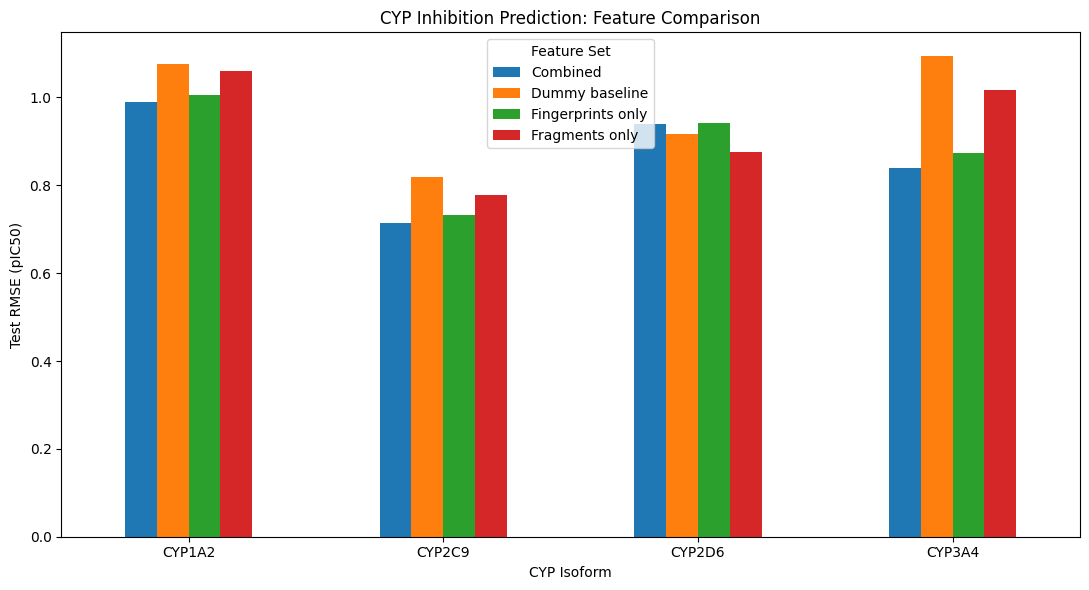

In [11]:
rmse_table = results_df.pivot(
    index="Isoform",
    columns="Model",
    values="RMSE"
)

display(rmse_table.round(3))

rmse_table.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("CYP Inhibition Prediction: Feature Comparison")
plt.ylabel("Test RMSE (pIC50)")
plt.xlabel("CYP Isoform")
plt.xticks(rotation=0)
plt.legend(title="Feature Set")
plt.tight_layout()
plt.show()

In [6]:
ablation_results = []

for isoform in isoforms:

    target = f"{isoform}_pIC50_direct_inhibition"

    y_all = pd.to_numeric(
        merged[target], errors="coerce"
    )

    valid = y_all.notna().to_numpy()
    y = y_all.loc[valid].to_numpy(dtype=float)

    indices = np.arange(len(y))

    train_idx, test_idx = train_test_split(
        indices,
        test_size=0.2,
        random_state=42
    )

    fingerprints = X_fingerprint[valid]
    fragments = X_fragments[valid]

    # Full model: fingerprints + all fragments
    full_X = np.hstack([fingerprints, fragments])

    full_model = Ridge(alpha=10.0)
    full_model.fit(full_X[train_idx], y[train_idx])

    full_pred = full_model.predict(full_X[test_idx])

    full_rmse = np.sqrt(
        mean_squared_error(y[test_idx], full_pred)
    )

    # Remove each fragment individually
    for i, fragment in enumerate(feature_cols):

        reduced_fragments = np.delete(
            fragments, i, axis=1
        )

        reduced_X = np.hstack([
            fingerprints, reduced_fragments
        ])

        model = Ridge(alpha=10.0)

        model.fit(
            reduced_X[train_idx],
            y[train_idx]
        )

        predictions = model.predict(
            reduced_X[test_idx]
        )

        reduced_rmse = np.sqrt(
            mean_squared_error(y[test_idx], predictions)
        )

        ablation_results.append({
            "Isoform": isoform,
            "Fragment": fragment,
            "Full_RMSE": full_rmse,
            "Without_RMSE": reduced_rmse,
            "RMSE_Increase": reduced_rmse - full_rmse
        })

ablation_df = pd.DataFrame(ablation_results)

display(
    ablation_df.sort_values(
        "RMSE_Increase",
        ascending=False
    ).round(4)
)

,Isoform,Fragment,Full_RMSE,Without_RMSE,RMSE_Increase
43,CYP3A4,carboxylic acid,0.8395,0.8674,0.0279
19,CYP2C9,carboxylic acid,0.7146,0.7237,0.0091
6,CYP1A2,basic aliphatic amine,0.9901,0.9972,0.0071
7,CYP1A2,carboxylic acid,0.9901,0.9954,0.0053
18,CYP2C9,basic aliphatic amine,0.7146,0.7183,0.0037
38,CYP3A4,pyridine,0.8395,0.8429,0.0034
42,CYP3A4,basic aliphatic amine,0.8395,0.8422,0.0027
16,CYP2C9,furan / thiophene,0.7146,0.7171,0.0024
2,CYP1A2,pyridine,0.9901,0.9924,0.0023
30,CYP2D6,basic aliphatic amine,0.9400,0.9416,0.0016


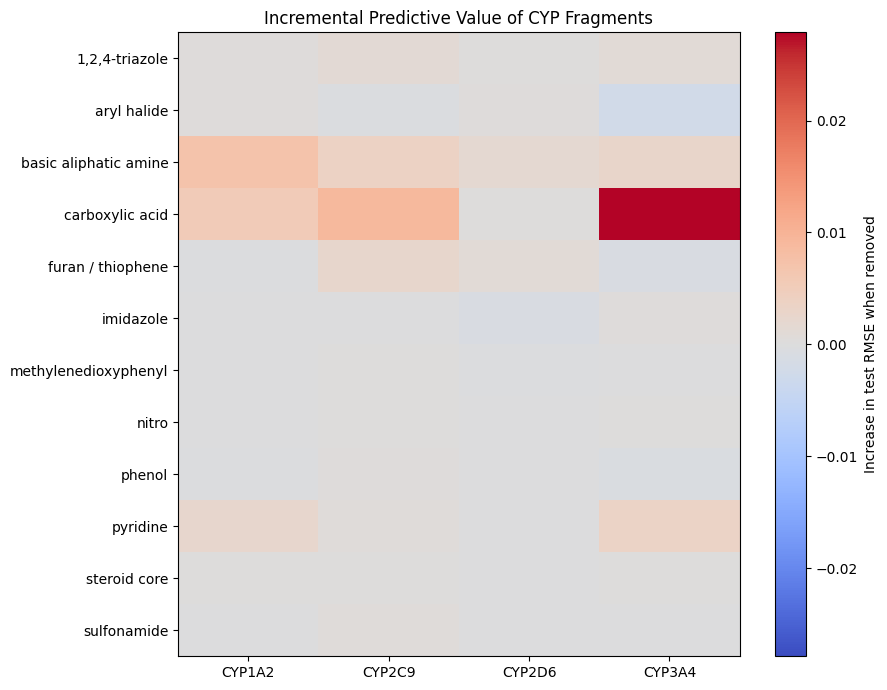

In [13]:
ablation_matrix = ablation_df.pivot(
    index="Fragment",
    columns="Isoform",
    values="RMSE_Increase"
)

plt.figure(figsize=(9, 7))

limit = np.nanmax(np.abs(ablation_matrix.to_numpy()))

plt.imshow(
    ablation_matrix,
    cmap="coolwarm",
    aspect="auto",
    vmin=-limit,
    vmax=limit
)

plt.colorbar(label="Increase in test RMSE when removed")

plt.xticks(
    range(len(ablation_matrix.columns)),
    ablation_matrix.columns
)

plt.yticks(
    range(len(ablation_matrix.index)),
    ablation_matrix.index
)

plt.title("Incremental Predictive Value of CYP Fragments")

plt.tight_layout()
plt.show()

## Feature Ablation Findings

Feature ablation was performed to evaluate the incremental predictive contribution of each CYP-relevant chemical group beyond Morgan fingerprints and the remaining fragment indicators.

Carboxylic acid showed the largest contribution, particularly for CYP3A4, where removing the feature increased test RMSE by 0.0279 (from 0.8395 to 0.8674). It also showed positive contributions for CYP2C9 and CYP1A2.

Basic aliphatic amine demonstrated smaller positive contributions for several isoforms, while most other fragments produced minimal changes in prediction error.

Interestingly, aryl halide showed a positive association with CYP3A4 inhibition in the exploratory analysis but did not improve predictive performance in the ablation experiment. This illustrates that associations with inhibition do not necessarily translate into additional predictive value.

Overall, carboxylic acid emerged as the strongest candidate for further investigation. However, these results are preliminary because they were obtained using a single random train/test split and a fixed Ridge regression configuration.

The next step is to evaluate the stability of these findings across multiple splits before determining which CYP-relevant fragments consistently improve inhibition prediction.

## Repeated-Split Feature Ablation

To assess the stability of the feature importance results,
we repeat the ablation experiment across 20 random train/test
splits.

For each split, we compare the full combined model against
models where one CYP fragment has been removed.

A positive RMSE increase indicates that the removed fragment
contributed to predictive performance in that split.

We examine both the average RMSE increase and how consistently
each fragment improves predictions.

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

import numpy as np
import pandas as pd

n_splits = 20
seeds = range(n_splits)

repeated_results = []

for isoform in isoforms:

    target = f"{isoform}_pIC50_direct_inhibition"

    y_all = pd.to_numeric(
        merged[target], errors="coerce"
    )

    valid = y_all.notna().to_numpy()
    y = y_all.loc[valid].to_numpy(dtype=float)

    fingerprints = X_fingerprint[valid]
    fragments = X_fragments[valid]

    full_X = np.hstack([fingerprints, fragments])

    for seed in seeds:

        train_idx, test_idx = train_test_split(
            np.arange(len(y)),
            test_size=0.2,
            random_state=seed
        )

        # Full model
        full_model = Ridge(alpha=10.0)

        full_model.fit(
            full_X[train_idx], y[train_idx]
        )

        full_pred = full_model.predict(
            full_X[test_idx]
        )

        full_rmse = np.sqrt(
            mean_squared_error(y[test_idx], full_pred)
        )

        # Remove one fragment at a time
        for i, fragment in enumerate(feature_cols):

            reduced_X = np.delete(
                full_X,
                fingerprints.shape[1] + i,
                axis=1
            )

            model = Ridge(alpha=10.0)

            model.fit(
                reduced_X[train_idx],
                y[train_idx]
            )

            pred = model.predict(reduced_X[test_idx])

            reduced_rmse = np.sqrt(
                mean_squared_error(y[test_idx], pred)
            )

            repeated_results.append({
                "Isoform": isoform,
                "Fragment": fragment,
                "Seed": seed,
                "RMSE_Increase": reduced_rmse - full_rmse
            })

    print(f"Completed {isoform}")

repeated_df = pd.DataFrame(repeated_results)

print("Total results:", len(repeated_df))

Completed CYP1A2
Completed CYP2C9
Completed CYP2D6
Completed CYP3A4
Total results: 960


In [15]:
summary_df = (
    repeated_df
    .groupby(["Isoform", "Fragment"])
    .agg(
        Mean_RMSE_Increase=("RMSE_Increase", "mean"),
        SD_RMSE_Increase=("RMSE_Increase", "std"),
        Positive_Splits=(
            "RMSE_Increase",
            lambda x: (x > 0).sum()
        )
    )
    .reset_index()
)

summary_df["Positive_Percent"] = (
    summary_df["Positive_Splits"] / n_splits * 100
)

summary_df = summary_df.sort_values(
    "Mean_RMSE_Increase",
    ascending=False
)

display(summary_df.round(4))

,Isoform,Fragment,Mean_RMSE_Increase,SD_RMSE_Increase,Positive_Splits,Positive_Percent
39,CYP3A4,carboxylic acid,0.0263,0.0070,20,100.0
26,CYP2D6,basic aliphatic amine,0.0102,0.0059,18,90.0
15,CYP2C9,carboxylic acid,0.0097,0.0041,20,100.0
3,CYP1A2,carboxylic acid,0.0042,0.0020,19,95.0
2,CYP1A2,basic aliphatic amine,0.0037,0.0037,15,75.0
16,CYP2C9,furan / thiophene,0.0028,0.0016,19,95.0
14,CYP2C9,basic aliphatic amine,0.0021,0.0040,15,75.0
45,CYP3A4,pyridine,0.0020,0.0014,19,95.0
37,CYP3A4,aryl halide,0.0019,0.0015,17,85.0
40,CYP3A4,furan / thiophene,0.0018,0.0012,19,95.0


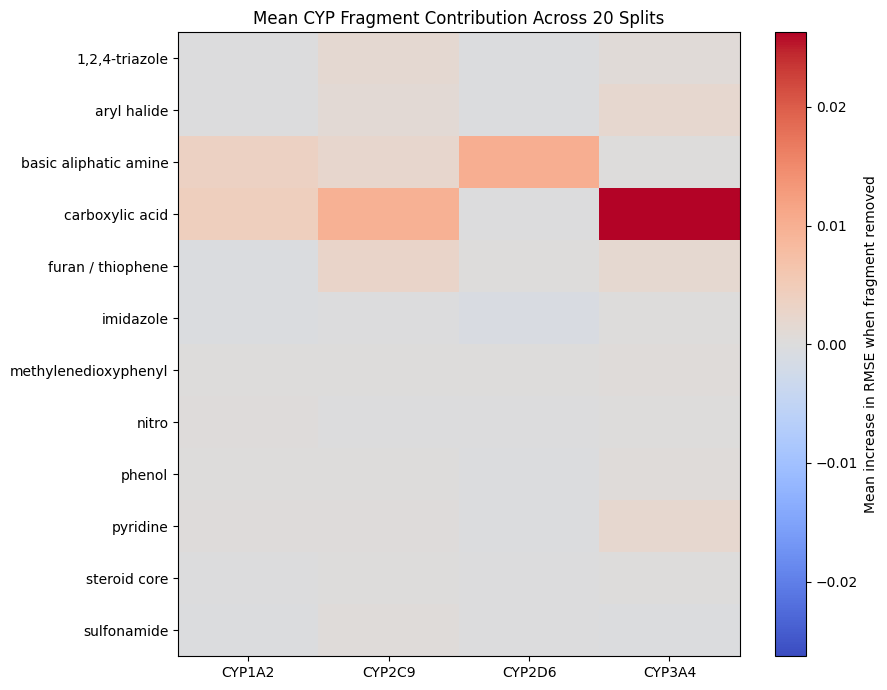

In [16]:
import matplotlib.pyplot as plt

mean_matrix = summary_df.pivot(
    index="Fragment",
    columns="Isoform",
    values="Mean_RMSE_Increase"
)

plt.figure(figsize=(9, 7))

limit = np.nanmax(np.abs(mean_matrix.to_numpy()))

plt.imshow(
    mean_matrix,
    cmap="coolwarm",
    aspect="auto",
    vmin=-limit,
    vmax=limit
)

plt.colorbar(
    label="Mean increase in RMSE when fragment removed"
)

plt.xticks(
    range(len(mean_matrix.columns)),
    mean_matrix.columns
)

plt.yticks(
    range(len(mean_matrix.index)),
    mean_matrix.index
)

plt.title("Mean CYP Fragment Contribution Across 20 Splits")

plt.tight_layout()
plt.show()

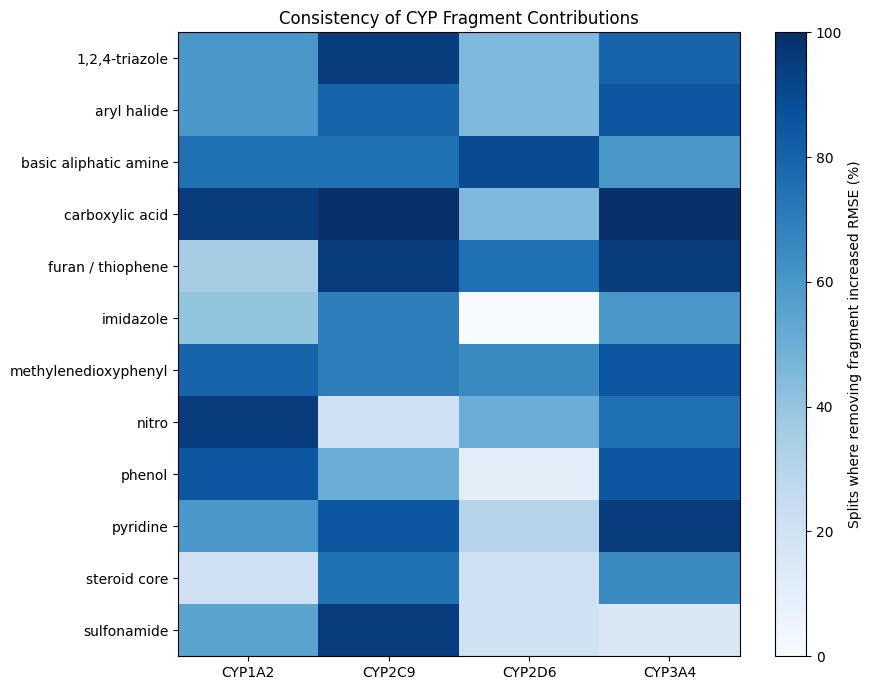

In [17]:
stability_matrix = summary_df.pivot(
    index="Fragment",
    columns="Isoform",
    values="Positive_Percent"
)

plt.figure(figsize=(9, 7))

plt.imshow(
    stability_matrix,
    cmap="Blues",
    aspect="auto",
    vmin=0,
    vmax=100
)

plt.colorbar(
    label="Splits where removing fragment increased RMSE (%)"
)

plt.xticks(
    range(len(stability_matrix.columns)),
    stability_matrix.columns
)

plt.yticks(
    range(len(stability_matrix.index)),
    stability_matrix.index
)

plt.title("Consistency of CYP Fragment Contributions")

plt.tight_layout()
plt.show()

## Repeated-Split Feature Ablation Findings

To assess the stability of the initial feature ablation results, the experiment was repeated across 20 random train/test splits using Ridge regression and Morgan fingerprints.

Carboxylic acid demonstrated the strongest incremental predictive contribution, especially for CYP3A4, where removing the feature increased RMSE by an average of 0.0263 (SD = 0.0070). This effect was observed in all 20 splits. Carboxylic acid also showed consistent positive contributions for CYP2C9 and CYP1A2.

Basic aliphatic amine was particularly informative for CYP2D6, where its removal increased RMSE by an average of 0.0102 across the 20 splits, with positive contributions in 18 splits.

Most other CYP-relevant fragments showed relatively small incremental contributions. Notably, imidazole showed little additional predictive value despite its observed association with inhibition potency in the earlier exploratory analysis. This suggests that the molecular fingerprints may already capture some of the structural information represented by explicit fragment indicators.

Overall, the results identify carboxylic acid and basic aliphatic amine as promising candidates for further feature evaluation. However, these findings remain specific to the current Ridge regression configuration and repeated random splits. Further validation is needed to determine whether the improvements generalize to structurally distinct molecules.

## Ridge Hyperparameter Tuning

Previous experiments used Ridge regression with a fixed alpha
of 10.

This experiment uses cross-validation to select alpha separately
for each CYP isoform and feature representation.

The goal is to determine whether the CYP fragment features
still improve prediction after model tuning.

Hyperparameter selection is performed only on training data.
The held-out test set is used for final evaluation.

In [18]:
import numpy as np
import pandas as pd

from sklearn.linear_model import Ridge
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    KFold
)
from sklearn.metrics import mean_squared_error, r2_score

In [19]:
alpha_grid = [0.1, 1, 10, 100, 1000]

feature_sets = {
    "Fragments only": X_fragments,
    "Fingerprints only": X_fingerprint,
    "Combined": X_combined
}

tuned_results = []

for isoform in isoforms:

    target = f"{isoform}_pIC50_direct_inhibition"

    y_all = pd.to_numeric(
        merged[target], errors="coerce"
    )

    valid = y_all.notna().to_numpy()
    y = y_all.loc[valid].to_numpy(dtype=float)

    indices = np.arange(len(y))

    train_idx, test_idx = train_test_split(
        indices,
        test_size=0.2,
        random_state=42
    )

    for name, X_all in feature_sets.items():

        X = X_all[valid]

        cv = KFold(
            n_splits=5,
            shuffle=True,
            random_state=42
        )

        search = GridSearchCV(
            estimator=Ridge(),
            param_grid={"alpha": alpha_grid},
            scoring="neg_root_mean_squared_error",
            cv=cv,
            n_jobs=-1
        )

        search.fit(X[train_idx], y[train_idx])

        predictions = search.predict(X[test_idx])

        tuned_results.append({
            "Isoform": isoform,
            "Model": name,
            "Best_Alpha": search.best_params_["alpha"],
            "RMSE": np.sqrt(mean_squared_error(
                y[test_idx], predictions
            )),
            "R2": r2_score(y[test_idx], predictions)
        })

    print(f"Completed {isoform}")

tuned_df = pd.DataFrame(tuned_results)

display(tuned_df.round(4))

Completed CYP1A2
Completed CYP2C9
Completed CYP2D6
Completed CYP3A4


,Isoform,Model,Best_Alpha,RMSE,R2
0,CYP1A2,Fragments only,1,1.0571,0.0348
1,CYP1A2,Fingerprints only,100,0.9491,0.2219
2,CYP1A2,Combined,100,0.9418,0.2339
3,CYP2C9,Fragments only,1,0.7760,0.1003
4,CYP2C9,Fingerprints only,100,0.7111,0.2445
5,CYP2C9,Combined,100,0.7001,0.2675
6,CYP2D6,Fragments only,10,0.8768,0.0868
7,CYP2D6,Fingerprints only,100,0.8550,0.1315
8,CYP2D6,Combined,100,0.8458,0.1503
9,CYP3A4,Fragments only,1,1.0169,0.1352


In [20]:
tuned_rmse = tuned_df.pivot(
    index="Isoform",
    columns="Model",
    values="RMSE"
)

tuned_rmse["Fragment_Improvement"] = (
    tuned_rmse["Fingerprints only"]
    - tuned_rmse["Combined"]
)

display(tuned_rmse.round(4))

Model,Combined,Fingerprints only,Fragments only,Fragment_Improvement
Isoform,,,,
CYP1A2,0.9418,0.9491,1.0571,0.0073
CYP2C9,0.7001,0.7111,0.7760,0.0109
CYP2D6,0.8458,0.8550,0.8768,0.0093
CYP3A4,0.8395,0.8728,1.0169,0.0334


In [21]:
from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold

def get_scaffold(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    scaffold = MurckoScaffold.MurckoScaffoldSmiles(
        mol=mol
    )

    # Acyclic molecules may have an empty Murcko scaffold.
    # Keep their canonical structures distinct.
    if not scaffold:
        return "acyclic:" + Chem.MolToSmiles(mol)

    return scaffold


merged["scaffold"] = merged["smiles"].apply(
    get_scaffold
)

print(
    "Unique scaffolds:",
    merged["scaffold"].nunique()
)

display(
    merged[["smiles", "scaffold"]].head()
)

Unique scaffolds: 4530


,smiles,scaffold
0,CC1=CC=C(N(CC2=NCCN2)C2=CC=CC(O)=C2)C=C1,c1ccc(N(CC2=NCCN2)c2ccccc2)cc1
1,C[C@H](CCC(=O)O)[C@H]1CC[C@H]2[C@@H]3CC[C@@H]4...,C1CCC2C(C1)CCC1C3CCCC3CCC21
2,[H][C@@]12CC[C@](O)(C(=O)CO)[C@@]1(C)C[C@H](O)...,O=C1C=C2CCC3C4CCCC4CCC3C2CC1
3,O=C(O)[C@@H](S)[C@@H](S)C(=O)O,acyclic:O=C(O)[C@@H](S)[C@@H](S)C(=O)O
4,CC1=CC=C(O)C=C1,c1ccccc1


In [22]:
from sklearn.model_selection import (
    GroupShuffleSplit,
    GroupKFold,
    GridSearchCV
)

scaffold_results = []

for isoform in isoforms:

    target = f"{isoform}_pIC50_direct_inhibition"

    y_all = pd.to_numeric(
        merged[target], errors="coerce"
    )

    valid = y_all.notna().to_numpy()

    y = y_all.loc[valid].to_numpy(dtype=float)
    groups = merged.loc[valid, "scaffold"].to_numpy()

    # Split by scaffold, not individual molecule
    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.2,
        random_state=42
    )

    train_idx, test_idx = next(
        splitter.split(
            X_fragments[valid],
            y,
            groups=groups
        )
    )

    # Verify no scaffold overlap
    train_scaffolds = set(groups[train_idx])
    test_scaffolds = set(groups[test_idx])

    assert train_scaffolds.isdisjoint(test_scaffolds)

    print(
        f"{isoform}: "
        f"{len(train_idx)} training, "
        f"{len(test_idx)} testing molecules"
    )

    cv = GroupKFold(n_splits=5)

    for name, X_all in feature_sets.items():

        X = X_all[valid]

        search = GridSearchCV(
            Ridge(),
            {"alpha": alpha_grid},
            scoring="neg_root_mean_squared_error",
            cv=cv,
            n_jobs=-1
        )

        search.fit(
            X[train_idx],
            y[train_idx],
            groups=groups[train_idx]
        )

        predictions = search.predict(
            X[test_idx]
        )

        scaffold_results.append({
            "Isoform": isoform,
            "Model": name,
            "Best_Alpha": search.best_params_["alpha"],
            "RMSE": np.sqrt(mean_squared_error(
                y[test_idx], predictions
            )),
            "R2": r2_score(
                y[test_idx], predictions
            )
        })

scaffold_df = pd.DataFrame(scaffold_results)

display(scaffold_df.round(4))

CYP1A2: 1131 training, 281 testing molecules
CYP2C9: 1029 training, 256 testing molecules
CYP2D6: 1178 training, 312 testing molecules
CYP3A4: 1884 training, 450 testing molecules


,Isoform,Model,Best_Alpha,RMSE,R2
0,CYP1A2,Fragments only,1,0.9873,0.0377
1,CYP1A2,Fingerprints only,100,0.9158,0.1722
2,CYP1A2,Combined,100,0.9121,0.1787
3,CYP2C9,Fragments only,10,0.7552,0.0594
4,CYP2C9,Fingerprints only,100,0.7004,0.1909
5,CYP2C9,Combined,100,0.6933,0.2073
6,CYP2D6,Fragments only,10,0.8491,0.0868
7,CYP2D6,Fingerprints only,100,0.8370,0.1127
8,CYP2D6,Combined,100,0.8284,0.1307
9,CYP3A4,Fragments only,1,0.9807,0.1760


In [23]:
scaffold_rmse = scaffold_df.pivot(
    index="Isoform",
    columns="Model",
    values="RMSE"
)

scaffold_rmse["Fragment_Improvement"] = (
    scaffold_rmse["Fingerprints only"]
    - scaffold_rmse["Combined"]
)

display(scaffold_rmse.round(4))

Model,Combined,Fingerprints only,Fragments only,Fragment_Improvement
Isoform,,,,
CYP1A2,0.9121,0.9158,0.9873,0.0036
CYP2C9,0.6933,0.7004,0.7552,0.0071
CYP2D6,0.8284,0.8370,0.8491,0.0086
CYP3A4,0.7645,0.7995,0.9807,0.0350


## Hyperparameter Tuning and Scaffold Validation Findings

Ridge regression hyperparameter tuning improved predictive performance across the CYP isoforms, with stronger regularization (alpha = 100) selected for CYP1A2, CYP2C9, and CYP2D6, while alpha = 10 remained optimal for CYP3A4.

Adding CYP-relevant fragment indicators to Morgan fingerprints reduced test RMSE for all four CYP isoforms in the tuned random-split evaluation. The largest improvement occurred for CYP3A4, where RMSE decreased from 0.8728 to 0.8395.

Scaffold-based evaluation showed a similar pattern, with the combined model outperforming the fingerprint-only model for all four isoforms. CYP3A4 again showed the largest improvement, with RMSE decreasing from 0.7995 to 0.7645 and R² increasing from 0.4524 to 0.4993.

These findings provide preliminary evidence that explicit CYP-relevant chemical group indicators can contribute predictive information beyond Morgan fingerprints, including for molecules with unseen scaffolds.

However, the results are based on one random split and one scaffold split for the tuned model comparisons. Further repeated scaffold-based validation and individual-fragment ablation are needed to determine which groups consistently provide the greatest incremental benefit.



## Repeated Scaffold-Based Feature Ablation

### Objective
Evaluate whether individual CYP-relevant chemical groups provide
additional predictive information beyond Morgan fingerprints when
testing on unseen molecular scaffolds.

### Method
- Generate multiple scaffold-grouped train/test splits.
- Tune Ridge regularization using training-only GroupKFold.
- Compare the full model against models with one fragment removed.
- Measure changes in held-out RMSE.
- Evaluate the stability of each fragment's contribution.

A positive RMSE increase indicates that removing the fragment
worsened predictive performance.

These results assess incremental predictive value, not
the biological importance of a fragment.

In [25]:
import numpy as np
import pandas as pd

from sklearn.model_selection import (
    GroupShuffleSplit,
    GroupKFold,
    GridSearchCV
)
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

# Start with 5 splits to test the pipeline.
# Change to 20 for the full experiment.
n_splits = 20

scaffold_ablation_results = []
scaffold_model_results = []

for isoform in isoforms:

    target = f"{isoform}_pIC50_direct_inhibition"

    y_all = pd.to_numeric(
        merged[target], errors="coerce"
    )

    valid = np.isfinite(y_all.to_numpy(dtype=float))

    y = y_all.to_numpy(dtype=float)[valid]
    groups = merged.loc[valid, "scaffold"].to_numpy()

    fingerprints = X_fingerprint[valid]
    fragments = X_fragments[valid]

    full_X = np.hstack([fingerprints, fragments])

    splitter = GroupShuffleSplit(
        n_splits=n_splits,
        test_size=0.2,
        random_state=42
    )

    for split_num, (train_idx, test_idx) in enumerate(
        splitter.split(full_X, y, groups=groups),
        start=1
    ):

        # Verify that training and test scaffolds do not overlap
        assert set(groups[train_idx]).isdisjoint(
            set(groups[test_idx])
        )

        # Cross-validation within training scaffolds
        cv = GroupKFold(n_splits=5)

        def fit_and_evaluate(X):

            search = GridSearchCV(
                Ridge(),
                {"alpha": alpha_grid},
                scoring="neg_root_mean_squared_error",
                cv=cv,
                n_jobs=-1
            )

            search.fit(
                X[train_idx],
                y[train_idx],
                groups=groups[train_idx]
            )

            predictions = search.predict(X[test_idx])

            rmse = np.sqrt(
                mean_squared_error(
                    y[test_idx],
                    predictions
                )
            )

            return rmse, search.best_params_["alpha"]

        # Fingerprint baseline
        fp_rmse, fp_alpha = fit_and_evaluate(
            fingerprints
        )

        # Full model: fingerprints + all fragments
        full_rmse, full_alpha = fit_and_evaluate(
            full_X
        )

        scaffold_model_results.append({
            "Isoform": isoform,
            "Split": split_num,
            "Fingerprint_RMSE": fp_rmse,
            "Combined_RMSE": full_rmse,
            "Combined_Improvement": fp_rmse - full_rmse,
            "N_Test": len(test_idx)
        })

        # Remove each CYP fragment individually
        for i, fragment in enumerate(feature_cols):

            reduced_X = np.delete(
                full_X,
                fingerprints.shape[1] + i,
                axis=1
            )

            reduced_rmse, reduced_alpha = (
                fit_and_evaluate(reduced_X)
            )

            scaffold_ablation_results.append({
                "Isoform": isoform,
                "Fragment": fragment,
                "Split": split_num,
                "Full_RMSE": full_rmse,
                "Without_RMSE": reduced_rmse,
                "RMSE_Increase": reduced_rmse - full_rmse,
                "Full_Alpha": full_alpha,
                "Reduced_Alpha": reduced_alpha
            })

        print(f"{isoform}: split {split_num}/{n_splits}")

scaffold_ablation_df = pd.DataFrame(
    scaffold_ablation_results
)

scaffold_model_df = pd.DataFrame(
    scaffold_model_results
)

print("Ablation rows:", len(scaffold_ablation_df))
display(scaffold_ablation_df.head())

CYP1A2: split 1/20
CYP1A2: split 2/20
CYP1A2: split 3/20
CYP1A2: split 4/20
CYP1A2: split 5/20
CYP1A2: split 6/20
CYP1A2: split 7/20
CYP1A2: split 8/20
CYP1A2: split 9/20
CYP1A2: split 10/20
CYP1A2: split 11/20
CYP1A2: split 12/20
CYP1A2: split 13/20
CYP1A2: split 14/20
CYP1A2: split 15/20
CYP1A2: split 16/20
CYP1A2: split 17/20
CYP1A2: split 18/20
CYP1A2: split 19/20
CYP1A2: split 20/20
CYP2C9: split 1/20
CYP2C9: split 2/20
CYP2C9: split 3/20
CYP2C9: split 4/20
CYP2C9: split 5/20
CYP2C9: split 6/20
CYP2C9: split 7/20
CYP2C9: split 8/20
CYP2C9: split 9/20
CYP2C9: split 10/20
CYP2C9: split 11/20
CYP2C9: split 12/20
CYP2C9: split 13/20
CYP2C9: split 14/20
CYP2C9: split 15/20
CYP2C9: split 16/20
CYP2C9: split 17/20
CYP2C9: split 18/20
CYP2C9: split 19/20
CYP2C9: split 20/20
CYP2D6: split 1/20
CYP2D6: split 2/20
CYP2D6: split 3/20
CYP2D6: split 4/20
CYP2D6: split 5/20
CYP2D6: split 6/20
CYP2D6: split 7/20
CYP2D6: split 8/20
CYP2D6: split 9/20
CYP2D6: split 10/20
CYP2D6: split 11/20
CYP2D6:

,Isoform,Fragment,Split,Full_RMSE,Without_RMSE,RMSE_Increase,Full_Alpha,Reduced_Alpha
0,CYP1A2,imidazole,1,0.912125,0.911624,-0.000501,100,100
1,CYP1A2,"1,2,4-triazole",1,0.912125,0.911670,-0.000455,100,100
2,CYP1A2,pyridine,1,0.912125,0.913738,0.001613,100,100
3,CYP1A2,methylenedioxyphenyl,1,0.912125,0.912231,0.000106,100,100
4,CYP1A2,furan / thiophene,1,0.912125,0.912165,0.000040,100,100


In [31]:
scaffold_summary = (
    scaffold_ablation_df
    .groupby(["Isoform", "Fragment"])
    .agg(
        Mean_RMSE_Increase=("RMSE_Increase", "mean"),
        SD_RMSE_Increase=("RMSE_Increase", "std"),
        Positive_Splits=(
            "RMSE_Increase",
            lambda x: (x > 0).sum()
        )
    )
    .reset_index()
)

scaffold_summary["Positive_Percent"] = (
    scaffold_summary["Positive_Splits"]
    / n_splits * 100
)

scaffold_summary = scaffold_summary.sort_values(
    "Mean_RMSE_Increase",
    ascending=False
)

display(scaffold_summary.round(4))

,Isoform,Fragment,Mean_RMSE_Increase,SD_RMSE_Increase,Positive_Splits,Positive_Percent
39,CYP3A4,carboxylic acid,0.0248,0.0045,20,100.0
26,CYP2D6,basic aliphatic amine,0.0142,0.0043,20,100.0
15,CYP2C9,carboxylic acid,0.0049,0.0016,20,100.0
37,CYP3A4,aryl halide,0.0023,0.0015,18,90.0
14,CYP2C9,basic aliphatic amine,0.0022,0.0015,18,90.0
2,CYP1A2,basic aliphatic amine,0.0020,0.0016,18,90.0
40,CYP3A4,furan / thiophene,0.0016,0.0015,17,85.0
16,CYP2C9,furan / thiophene,0.0016,0.0008,20,100.0
45,CYP3A4,pyridine,0.0015,0.0015,18,90.0
3,CYP1A2,carboxylic acid,0.0009,0.0007,18,90.0


In [33]:
model_summary = (
    scaffold_model_df
    .groupby("Isoform")
    .agg(
        Mean_Fingerprint_RMSE=("Fingerprint_RMSE", "mean"),
        Mean_Combined_RMSE=("Combined_RMSE", "mean"),
        Mean_Improvement=("Combined_Improvement", "mean"),
        Positive_Splits=(
            "Combined_Improvement",
            lambda x: (x > 0).sum()
        )
    )
    .reset_index()
)

display(model_summary.round(4))

,Isoform,Mean_Fingerprint_RMSE,Mean_Combined_RMSE,Mean_Improvement,Positive_Splits
0,CYP1A2,0.9116,0.9081,0.0035,18
1,CYP2C9,0.6990,0.6894,0.0096,20
2,CYP2D6,0.8640,0.8504,0.0136,20
3,CYP3A4,0.8457,0.8136,0.0321,20


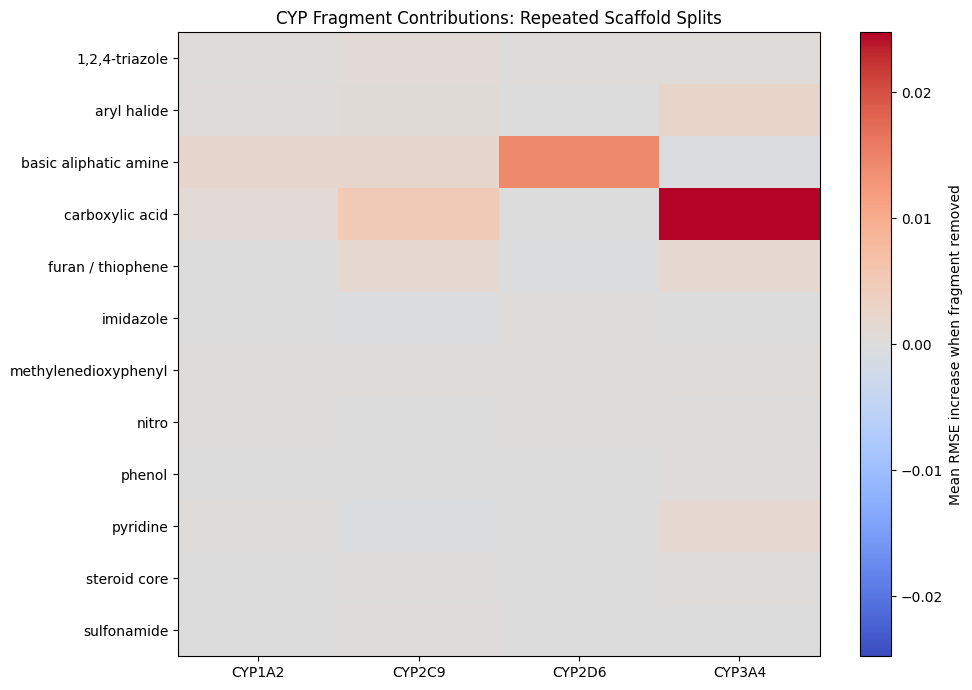

In [35]:
import matplotlib.pyplot as plt

matrix = scaffold_summary.pivot(
    index="Fragment",
    columns="Isoform",
    values="Mean_RMSE_Increase"
)

plt.figure(figsize=(10, 7))

limit = np.nanmax(np.abs(matrix.to_numpy()))

plt.imshow(
    matrix,
    cmap="coolwarm",
    aspect="auto",
    vmin=-limit,
    vmax=limit
)

plt.colorbar(
    label="Mean RMSE increase when fragment removed"
)

plt.xticks(
    range(len(matrix.columns)),
    matrix.columns
)

plt.yticks(
    range(len(matrix.index)),
    matrix.index
)

plt.title(
    "CYP Fragment Contributions: Repeated Scaffold Splits"
)

plt.tight_layout()
plt.show()

In [36]:
comparison_df = summary_df[
    ["Isoform", "Fragment", "Mean_RMSE_Increase"]
].merge(
    scaffold_summary[
        ["Isoform", "Fragment", "Mean_RMSE_Increase"]
    ],
    on=["Isoform", "Fragment"],
    suffixes=("_Random", "_Scaffold")
)

comparison_df = comparison_df.sort_values(
    "Mean_RMSE_Increase_Scaffold",
    ascending=False
)

display(comparison_df.round(4))

,Isoform,Fragment,Mean_RMSE_Increase_Random,Mean_RMSE_Increase_Scaffold
0,CYP3A4,carboxylic acid,0.0263,0.0248
1,CYP2D6,basic aliphatic amine,0.0102,0.0142
2,CYP2C9,carboxylic acid,0.0097,0.0049
8,CYP3A4,aryl halide,0.0019,0.0023
6,CYP2C9,basic aliphatic amine,0.0021,0.0022
4,CYP1A2,basic aliphatic amine,0.0037,0.0020
9,CYP3A4,furan / thiophene,0.0018,0.0016
5,CYP2C9,furan / thiophene,0.0028,0.0016
7,CYP3A4,pyridine,0.0020,0.0015
3,CYP1A2,carboxylic acid,0.0042,0.0009


In [37]:
from pathlib import Path

results_dir = Path("../results/tables")
results_dir.mkdir(parents=True, exist_ok=True)

scaffold_summary.to_csv(
    results_dir / "scaffold_ablation_summary.csv",
    index=False
)

model_summary.to_csv(
    results_dir / "scaffold_model_comparison.csv",
    index=False
)

comparison_df.to_csv(
    results_dir / "random_vs_scaffold_ablation.csv",
    index=False
)

## Repeated Scaffold-Based Ablation Findings

Repeated scaffold-based feature ablation was performed across 20 train/test splits to investigate whether CYP-relevant fragment indicators contribute predictive information for molecules with unseen chemical scaffolds.

Adding the 12 CYP-relevant fragments to Morgan fingerprints reduced average RMSE across all four CYP isoforms. The greatest improvement occurred for CYP3A4, where RMSE decreased from 0.8457 to 0.8136, representing approximately a 3.8% reduction. Improvements were observed in all 20 scaffold splits for CYP3A4, CYP2C9, and CYP2D6.

Individual feature ablation identified carboxylic acid as the strongest contributor for CYP3A4, with an average RMSE increase of 0.0248 when removed. Basic aliphatic amine was the strongest contributor for CYP2D6 (+0.0142), while carboxylic acid also contributed to CYP2C9 (+0.0049). All three features demonstrated positive contributions across all 20 scaffold splits.

Most other fragment indicators produced relatively small improvements, suggesting that Morgan fingerprints already capture substantial chemical information represented by these groups.

Overall, the results suggest that selected CYP-relevant chemical groups provide additional predictive information beyond standard molecular fingerprints, with contributions varying across CYP isoforms. These findings are specific to the current Ridge regression approach and should be validated with additional models and careful assessment of dataset limitations.

## Random Forest Feature Evaluation

### Objective
Determine whether CYP-relevant chemical groups provide additional
predictive information when using a nonlinear machine learning model.

### Method
1. Verify molecular matching and inhibition label quality.
2. Compare Random Forest models using fingerprints alone
   versus fingerprints plus 12 CYP fragments.
3. Evaluate using repeated scaffold-based splits.
4. Investigate individual fragment contributions.

This experiment tests whether the findings from Ridge regression
generalize to a different model architecture.